# 🎬 Projet : Classification Multi-Label de Films par Genre
### Naive Bayes + BERT — Dataset IMDB 5000
---
**Structure du notebook :**
1. 📦 Imports & Configuration
2. 📥 Chargement des données
3. 🔧 Traitements & Préparation des features
4. 🎯 Entraînement des modèles
5. 📊 Résultats & Comparaison (Bayésien / BERT / Bayésien+BERT)
6. 🖥️ Interface graphique interactive

In [3]:
# ============================================================
# 📦 CELLULE 1 — IMPORTS & CONFIGURATION
# ============================================================

# ── Installation des dépendances ─────────────────────────────
!pip install kagglehub -q
!pip install -U transformers -q
!pip install ipywidgets -q
!pip install tqdm -q

# ── Librairies standard & data ────────────────────────────────
import kagglehub
import pandas as pd
import numpy as np
import warnings
import random
import os
from pathlib import Path

warnings.filterwarnings('ignore')

# ── Visualisation ─────────────────────────────────────────────
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 11

# ── Machine Learning ──────────────────────────────────────────
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB, BernoulliNB
from sklearn.multiclass import OneVsRestClassifier
from sklearn.preprocessing import StandardScaler, MultiLabelBinarizer
import pandas.api.types as pdt

# ── Metriques ─────────────────────────────────────────────────
from sklearn.metrics import (
    classification_report, accuracy_score, f1_score,
    precision_score, recall_score, hamming_loss,
    jaccard_score, multilabel_confusion_matrix,
    label_ranking_loss, label_ranking_average_precision_score,
    coverage_error
)

# ── NLP / BERT ────────────────────────────────────────────────
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel
from tqdm.notebook import tqdm

# ── Interface graphique ───────────────────────────────────────
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

# ── Config BERT ───────────────────────────────────────────────
DEVICE       = 'cuda' if torch.cuda.is_available() else 'cpu'
MODEL_NAME   = 'distilbert-base-uncased'
GENRE_NAMES  = ['Drama', 'Comedy', 'Thriller', 'Action', 'Romance', 'Adventure', 'Crime']
THRESHOLD    = 0.3
MODELS_DIR   = 'models'
os.makedirs(MODELS_DIR, exist_ok=True)

print('✅ Tous les imports effectués avec succès !')
print(f'🖥️  Device : {DEVICE.upper()}')


✅ Tous les imports effectués avec succès !
🖥️  Device : CPU


In [4]:
# ============================================================
# 📥 CELLULE 2 — CHARGEMENTS
# ============================================================

# ── 2.1 Dataset IMDB ─────────────────────────────────────────
print('=' * 70)
print('📥 CHARGEMENT DU DATASET IMDB 5000')
print('=' * 70)

path = kagglehub.dataset_download('carolzhangdc/imdb-5000-movie-dataset')
df_raw = pd.read_csv(os.path.join(path, 'movie_metadata.csv'))

print(f'✅ Dataset chargé : {df_raw.shape[0]} films, {df_raw.shape[1]} colonnes')
print('\n📊 Aperçu :')
display(df_raw[['movie_title','genres','imdb_score','budget','gross']].head(10))

# ── 2.2 Définition du modèle BERT multi-label ────────────────
print('\n' + '=' * 70)
print('🤖 DÉFINITION DU MODÈLE BERT MULTI-LABEL')
print('=' * 70)

class BERTMultiLabel(nn.Module):
    def __init__(self, n_labels=7, dropout=0.3):
        super().__init__()
        self.bert = AutoModel.from_pretrained(MODEL_NAME)
        self.drop = nn.Dropout(dropout)
        self.fc   = nn.Linear(self.bert.config.hidden_size, n_labels)
    def forward(self, input_ids, attention_mask):
        out = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        cls = out.last_hidden_state[:, 0, :]
        return self.fc(self.drop(cls))

def build_text(row):
    parts = []
    if pd.notna(row.get('movie_title')): parts.append(str(row['movie_title']).strip())
    if pd.notna(row.get('director_name')): parts.append(f"directed by {row['director_name']}")
    actors = [row.get(c) for c in ['actor_1_name','actor_2_name','actor_3_name'] if pd.notna(row.get(c))]
    if actors: parts.append(f"starring {', '.join(str(a) for a in actors)}")
    if pd.notna(row.get('plot_keywords')):
        parts.append(str(row['plot_keywords']).replace('|', ' '))
    if pd.notna(row.get('content_rating')): parts.append(f"rated {row['content_rating']}")
    return '. '.join(parts)

# ── 2.3 Chargement ou entraînement BERT ──────────────────────
print('\n' + '=' * 70)
print('📥 CHARGEMENT DES PRÉDICTIONS BERT (modèle fine-tuné)')
print('=' * 70)

BERT_MODEL_PATH = os.path.join(MODELS_DIR, 'bert_multilabel.pth')
BERT_PRED_PATH  = os.path.join(MODELS_DIR, 'y_pred_bert.npy')
BERT_TRUE_PATH  = os.path.join(MODELS_DIR, 'y_true_bert.npy')

if os.path.exists(BERT_PRED_PATH) and os.path.exists(BERT_TRUE_PATH):
    print('📂 Fichiers de prédictions trouvés, chargement...')
    y_pred_bert_saved = np.load(BERT_PRED_PATH)
    y_true_bert_saved = np.load(BERT_TRUE_PATH)
    f1_bert = f1_score(y_true_bert_saved, y_pred_bert_saved, average='micro', zero_division=0)
    print(f'✅ Prédictions BERT chargées : {y_pred_bert_saved.shape[0]} films')
    print(f'✅ F1 micro BERT (fine-tuné) : {f1_bert:.4f}')
    print('\nF1 par genre :')
    for i, g in enumerate(GENRE_NAMES):
        f = f1_score(y_true_bert_saved[:,i], y_pred_bert_saved[:,i], zero_division=0)
        bar = chr(9608) * int(f * 30)
        print(f'  {g:<12s} {f:.4f}  {bar}')
else:
    print('⚠️  Fichiers introuvables. Placez bert_multilabel.pth, y_pred_bert.npy')
    print('    et y_true_bert.npy dans le dossier "models/" puis relancez.')
    y_pred_bert_saved = None
    y_true_bert_saved = None


📥 CHARGEMENT DU DATASET IMDB 5000
Using Colab cache for faster access to the 'imdb-5000-movie-dataset' dataset.
✅ Dataset chargé : 5043 films, 28 colonnes

📊 Aperçu :


,movie_title,genres,imdb_score,budget,gross
0,Avatar,Action|Adventure|Fantasy|Sci-Fi,7.9,237000000.0,760505847.0
1,Pirates of the Caribbean: At World's End,Action|Adventure|Fantasy,7.1,300000000.0,309404152.0
2,Spectre,Action|Adventure|Thriller,6.8,245000000.0,200074175.0
3,The Dark Knight Rises,Action|Thriller,8.5,250000000.0,448130642.0
4,Star Wars: Episode VII - The Force Awakens ...,Documentary,7.1,NaN,NaN
5,John Carter,Action|Adventure|Sci-Fi,6.6,263700000.0,73058679.0
6,Spider-Man 3,Action|Adventure|Romance,6.2,258000000.0,336530303.0
7,Tangled,Adventure|Animation|Comedy|Family|Fantasy|Musi...,7.8,260000000.0,200807262.0
8,Avengers: Age of Ultron,Action|Adventure|Sci-Fi,7.5,250000000.0,458991599.0
9,Harry Potter and the Half-Blood Prince,Adventure|Family|Fantasy|Mystery,7.5,250000000.0,301956980.0



🤖 DÉFINITION DU MODÈLE BERT MULTI-LABEL

📥 CHARGEMENT DES PRÉDICTIONS BERT (modèle fine-tuné)
📂 Fichiers de prédictions trouvés, chargement...
✅ Prédictions BERT chargées : 1009 films
✅ F1 micro BERT (fine-tuné) : 0.6841

F1 par genre :
  Drama        0.7551  ██████████████████████
  Comedy       0.7011  █████████████████████
  Thriller     0.6775  ████████████████████
  Action       0.6772  ████████████████████
  Romance      0.5729  █████████████████
  Adventure    0.6530  ███████████████████
  Crime        0.6161  ██████████████████


In [6]:
# ============================================================
# 🔧 CELLULE 3 — TRAITEMENTS & PRÉPARATION DES FEATURES
# ============================================================

# ── 3.1 Nettoyage de base ─────────────────────────────────────
print('=' * 70)
print('🔧 3.1  NETTOYAGE & ANALYSE DU FORMAT MULTI-LABEL')
print('=' * 70)

df = df_raw.copy()
df = df.dropna(subset=['genres'])
df['genres_list'] = df['genres'].str.split('|')
df['nb_genres']   = df['genres_list'].str.len()

print(f'Minimum de genres par film : {df["nb_genres"].min()}')
print(f'Maximum de genres par film : {df["nb_genres"].max()}')
print(f'Moyenne                    : {df["nb_genres"].mean():.1f}')
print('\nExemples multi-genres :')
for _, row in df[['movie_title','genres']].head(6).iterrows():
    print(f'  {row["movie_title"]:<35s} -> {row["genres"].split("|")}')

# ── 3.2 One-Hot Encoding des genres (target Y) ───────────────
print('\n' + '=' * 70)
print('🔧 3.2  ONE-HOT ENCODING DES GENRES (TARGET Y)')
print('=' * 70)

mlb = MultiLabelBinarizer()
genres_encoded = mlb.fit_transform(df['genres_list'])
genres_df = pd.DataFrame(genres_encoded, columns=mlb.classes_, index=df.index)

genre_freq = genres_df.sum().sort_values(ascending=False)
print(f'\n{len(mlb.classes_)} genres uniques détectés :')
for genre, count in genre_freq.items():
    pct = count / len(df) * 100
    bar = chr(9608) * int(pct / 2)
    print(f'  {genre:<20s} {count:>4.0f} films ({pct:>5.1f}%)  {bar}')

MIN_GENRE_SAMPLES = 800
genres_to_keep = genre_freq[genre_freq >= MIN_GENRE_SAMPLES].index.tolist()
genres_to_drop = genre_freq[genre_freq <  MIN_GENRE_SAMPLES].index.tolist()
print(f'\n✅ Genres gardes  ({len(genres_to_keep)}) : {genres_to_keep}')
print(f'❌ Genres exclus  ({len(genres_to_drop)}) : {genres_to_drop}')

y_multilabel = genres_df[genres_to_keep].values
genre_names  = genres_to_keep
print(f'\n✅ Matrice cible Y : {y_multilabel.shape}')

# ── 3.3 Features numériques & imputation ─────────────────────
print('\n' + '=' * 70)
print('🔧 3.3  FEATURES NUMÉRIQUES')
print('=' * 70)

features_disponibles = [col for col in df.columns if pdt.is_numeric_dtype(df[col])]
features_disponibles.remove('aspect_ratio')

X_df = df[features_disponibles].copy()
for col in features_disponibles:
    median_val = X_df[col].median()
    n_filled   = X_df[col].isna().sum()
    X_df[col].fillna(median_val, inplace=True)
    if n_filled > 0:
        print(f'  {col}: {n_filled} valeurs manquantes -> mediane={median_val:.0f}')

valid_mask   = X_df.notna().all(axis=1)
X_df         = X_df[valid_mask]
y_multilabel = y_multilabel[valid_mask.values]
df_valid     = df.loc[valid_mask.index].copy()
print(f'\n✅ Dataset final : {len(X_df)} films, {len(features_disponibles)} features numériques')

# ── 3.4 Intégration des prédictions BERT fine-tuné ───────────
print('\n' + '=' * 70)
print('🔧 3.4  INTÉGRATION PRÉDICTIONS BERT FINE-TUNÉ (MULTI-LABEL)')
print('=' * 70)

# Reconstruction de l'index test BERT (même split que l'entraînement)
idx_all = np.arange(len(df_valid))
_, idx_te_bert = train_test_split(idx_all, test_size=0.20, random_state=42)

bert_ohe_full = np.zeros((len(df_valid), len(GENRE_NAMES)), dtype=int)

if y_pred_bert_saved is not None:
    # Remplir les lignes test avec les prédictions BERT
    for local_i, global_i in enumerate(idx_te_bert):
        bert_ohe_full[global_i, :] = y_pred_bert_saved[local_i, :]
    print(f'✅ Prédictions BERT insérées pour {len(idx_te_bert)} films (set test)')
else:
    print('⚠️  Prédictions BERT non disponibles — colonne BERT = zéros')

bert_ohe_df = pd.DataFrame(
    bert_ohe_full,
    columns=[f'BERT_{g}' for g in GENRE_NAMES],
    index=df_valid.index
)

print(f'✅ Features BERT : {bert_ohe_df.shape[1]} colonnes')
print('\nDistribution des prédictions BERT par genre :')
for g in GENRE_NAMES:
    col = f'BERT_{g}'
    n   = bert_ohe_df[col].sum()
    pct = n / len(bert_ohe_df) * 100
    print(f'  {g:<12s} {n:>4} films ({pct:>5.1f}%)')

# ── 3.5 Combinaison features numériques + BERT ───────────────
print('\n' + '=' * 70)
print('🔧 3.5  COMBINAISON FEATURES NUMÉRIQUES + BERT')
print('=' * 70)

X_combined = pd.concat(
    [X_df.reset_index(drop=True), bert_ohe_df.reset_index(drop=True)],
    axis=1
)
print(f'✅ X_combined : {X_combined.shape[0]} films x {X_combined.shape[1]} features')
display(X_combined.head())

# ── 3.6 Split Train/Test + normalisation ─────────────────────
print('\n' + '=' * 70)
print('🔧 3.6  SPLIT TRAIN/TEST & NORMALISATION')
print('=' * 70)

X = X_combined.values
y = y_multilabel

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

scaler_std     = StandardScaler()
X_train_scaled = scaler_std.fit_transform(X_train)
X_test_scaled  = scaler_std.transform(X_test)

# Récupérer les indices test (alignement avec BERT)
_, _, _, _, idx_tr_global, idx_te_global = train_test_split(
    X, y, np.arange(len(X)), test_size=0.20, random_state=42
)

print(f'  X_train : {X_train.shape}   X_test : {X_test.shape}')
print(f'  y_train : {y_train.shape}   y_test : {y_test.shape}')
print('\nDistribution genres train/test :')
print(f'  {"Genre":<20s} {"Train":>6s} {"Test":>6s}')
print('  ' + '-' * 35)
for i, genre in enumerate(genre_names):
    print(f'  {genre:<20s} {y_train[:,i].sum():>6.0f} {y_test[:,i].sum():>6.0f}')
print('\n✅ Données prêtes pour l entraînement !')


🔧 3.1  NETTOYAGE & ANALYSE DU FORMAT MULTI-LABEL
Minimum de genres par film : 1
Maximum de genres par film : 8
Moyenne                    : 2.9

Exemples multi-genres :
  Avatar                              -> ['Action', 'Adventure', 'Fantasy', 'Sci-Fi']
  Pirates of the Caribbean: At World's End  -> ['Action', 'Adventure', 'Fantasy']
  Spectre                             -> ['Action', 'Adventure', 'Thriller']
  The Dark Knight Rises               -> ['Action', 'Thriller']
  Star Wars: Episode VII - The Force Awakens              -> ['Documentary']
  John Carter                         -> ['Action', 'Adventure', 'Sci-Fi']

🔧 3.2  ONE-HOT ENCODING DES GENRES (TARGET Y)

26 genres uniques détectés :
  Drama                2594 films ( 51.4%)  █████████████████████████
  Comedy               1872 films ( 37.1%)  ██████████████████
  Thriller             1411 films ( 28.0%)  █████████████
  Action               1153 films ( 22.9%)  ███████████
  Romance              1107 films ( 22.0%)  ██

,num_critic_for_reviews,duration,director_facebook_likes,actor_3_facebook_likes,actor_1_facebook_likes,gross,num_voted_users,cast_total_facebook_likes,facenumber_in_poster,num_user_for_reviews,...,imdb_score,movie_facebook_likes,nb_genres,BERT_Drama,BERT_Comedy,BERT_Thriller,BERT_Action,BERT_Romance,BERT_Adventure,BERT_Crime
0,723.0,178.0,0.0,855.0,1000.0,760505847.0,886204,4834,0.0,3054.0,...,7.9,33000,4,0,0,0,0,0,0,0
1,302.0,169.0,563.0,1000.0,40000.0,309404152.0,471220,48350,0.0,1238.0,...,7.1,0,3,0,0,0,0,0,0,0
2,602.0,148.0,0.0,161.0,11000.0,200074175.0,275868,11700,1.0,994.0,...,6.8,85000,3,0,0,0,0,0,0,0
3,813.0,164.0,22000.0,23000.0,27000.0,448130642.0,1144337,106759,0.0,2701.0,...,8.5,164000,2,0,0,0,0,0,0,0
4,110.0,103.0,131.0,371.5,131.0,25517500.0,8,143,0.0,156.0,...,7.1,0,1,0,0,0,0,0,0,0



🔧 3.6  SPLIT TRAIN/TEST & NORMALISATION
  X_train : (4034, 23)   X_test : (1009, 23)
  y_train : (4034, 7)   y_test : (1009, 7)

Distribution genres train/test :
  Genre                 Train   Test
  -----------------------------------
  Drama                  2081    513
  Comedy                 1516    356
  Thriller               1122    289
  Action                  938    215
  Romance                 882    225
  Adventure               745    178
  Crime                   717    172

✅ Données prêtes pour l entraînement !


In [7]:
# ============================================================
# 🎯 CELLULE 4 — ENTRAÎNEMENT DES MODÈLES
# ============================================================

# ── 4.1 GaussianNB ───────────────────────────────────────────
print('=' * 70)
print('🔹 4.1  OneVsRest + GaussianNB')
print('=' * 70)

gnb_ovr = OneVsRestClassifier(GaussianNB())
gnb_ovr.fit(X_train_scaled, y_train)
print(f'✅ {len(gnb_ovr.estimators_)} classifieurs entraînés')
print('Probabilités a priori par genre :')
for i, genre in enumerate(genre_names):
    prior = gnb_ovr.estimators_[i].class_prior_[1]
    print(f'  {genre:<20s}  P(genre) = {prior:.4f}')

# ── 4.2 BernoulliNB ──────────────────────────────────────────
print('\n' + '=' * 70)
print('🔹 4.2  OneVsRest + BernoulliNB')
print('=' * 70)

bnb_ovr = OneVsRestClassifier(BernoulliNB(alpha=1.0))
bnb_ovr.fit(X_train_scaled, y_train)
print(f'✅ {len(bnb_ovr.estimators_)} classifieurs entraînés')

# ── 4.3 Stockage + prédictions sur le test set ───────────────
print('\n' + '=' * 70)
print('🔹 4.3  PRÉDICTIONS SUR LE JEU DE TEST')
print('=' * 70)

models = {
    'GaussianNB':  {'model': gnb_ovr, 'X_train': X_train_scaled, 'X_test': X_test_scaled},
    'BernoulliNB': {'model': bnb_ovr, 'X_train': X_train_scaled, 'X_test': X_test_scaled},
}

predictions = {}
for name, info in models.items():
    y_pred = info['model'].predict(info['X_test'])
    predictions[name] = y_pred
    print(f'  {name:<15s} -> {y_pred.sum(axis=1).mean():.1f} genres/film en moyenne')

# ── 4.4 Paramètres internes GaussianNB ───────────────────────
print('\n' + '=' * 70)
print('🔹 4.4  PARAMÈTRES INTERNES GaussianNB (mu +/- sigma par genre)')
print('=' * 70)

for i, genre in enumerate(genre_names):
    est = gnb_ovr.estimators_[i]
    print(f'\n--- Genre : {genre}  (P(genre)={est.class_prior_[1]:.4f}) ---')
    print(f'  {"Feature":<35s} {"Moyenne":>10s} {"Ecart-type":>12s}')
    print('  ' + '-' * 58)
    for j, feature in enumerate(features_disponibles):
        mean_v = est.theta_[1, j]
        std_v  = np.sqrt(est.var_[1, j])
        print(f'  {feature:<35s} {mean_v:>10.4f} {std_v:>12.4f}')

print('\n✅ Entraînement terminé !')


🔹 4.1  OneVsRest + GaussianNB
✅ 7 classifieurs entraînés
Probabilités a priori par genre :
  Drama                 P(genre) = 0.5159
  Comedy                P(genre) = 0.3758
  Thriller              P(genre) = 0.2781
  Action                P(genre) = 0.2325
  Romance               P(genre) = 0.2186
  Adventure             P(genre) = 0.1847
  Crime                 P(genre) = 0.1777

🔹 4.2  OneVsRest + BernoulliNB
✅ 7 classifieurs entraînés

🔹 4.3  PRÉDICTIONS SUR LE JEU DE TEST
  GaussianNB      -> 2.7 genres/film en moyenne
  BernoulliNB     -> 4.6 genres/film en moyenne

🔹 4.4  PARAMÈTRES INTERNES GaussianNB (mu +/- sigma par genre)

--- Genre : Drama  (P(genre)=0.5159) ---
  Feature                                Moyenne   Ecart-type
  ----------------------------------------------------------
  num_critic_for_reviews                 -0.0264       0.9957
  duration                                0.2254       1.1239
  director_facebook_likes                 0.0240       1.0798
  acto

📊 5.1  MÉTRIQUES COMPARATIVES — TOUS LES MODÈLES

📊 TABLEAU COMPARATIF COMPLET :


,Precision (macro),Precision (samples),Precision (micro),False Positives Rate,Label Ranking Loss,Label Ranking Avg Precision,Coverage Error,False Discovery Rate,Hamming Loss,Jaccard (macro),Jaccard (samples),Recall (macro),Recall (micro),Exact Match (Accuracy),F1-Score (micro)
GaussianNB,0.4150,0.4133,0.4180,0.3150,0.5282,0.5059,4.9703,0.5820,0.3401,0.2920,0.3556,0.5310,0.5939,0.0872,0.4907
BernoulliNB,0.3596,0.3354,0.3362,0.6045,0.6796,0.4130,5.3865,0.6638,0.4919,0.3171,0.3153,0.8345,0.8039,0.0248,0.4741
BERT fine-tuné,0.6146,0.6327,0.6236,0.1742,0.3196,0.6618,4.0585,0.3764,0.1930,0.5003,0.5473,0.7398,0.7577,0.2329,0.6841



🏆 Meilleur modele (F1 micro) : BERT fine-tuné (0.6841)

📊 5.2  VISUALISATION COMPARAISON DES APPROCHES


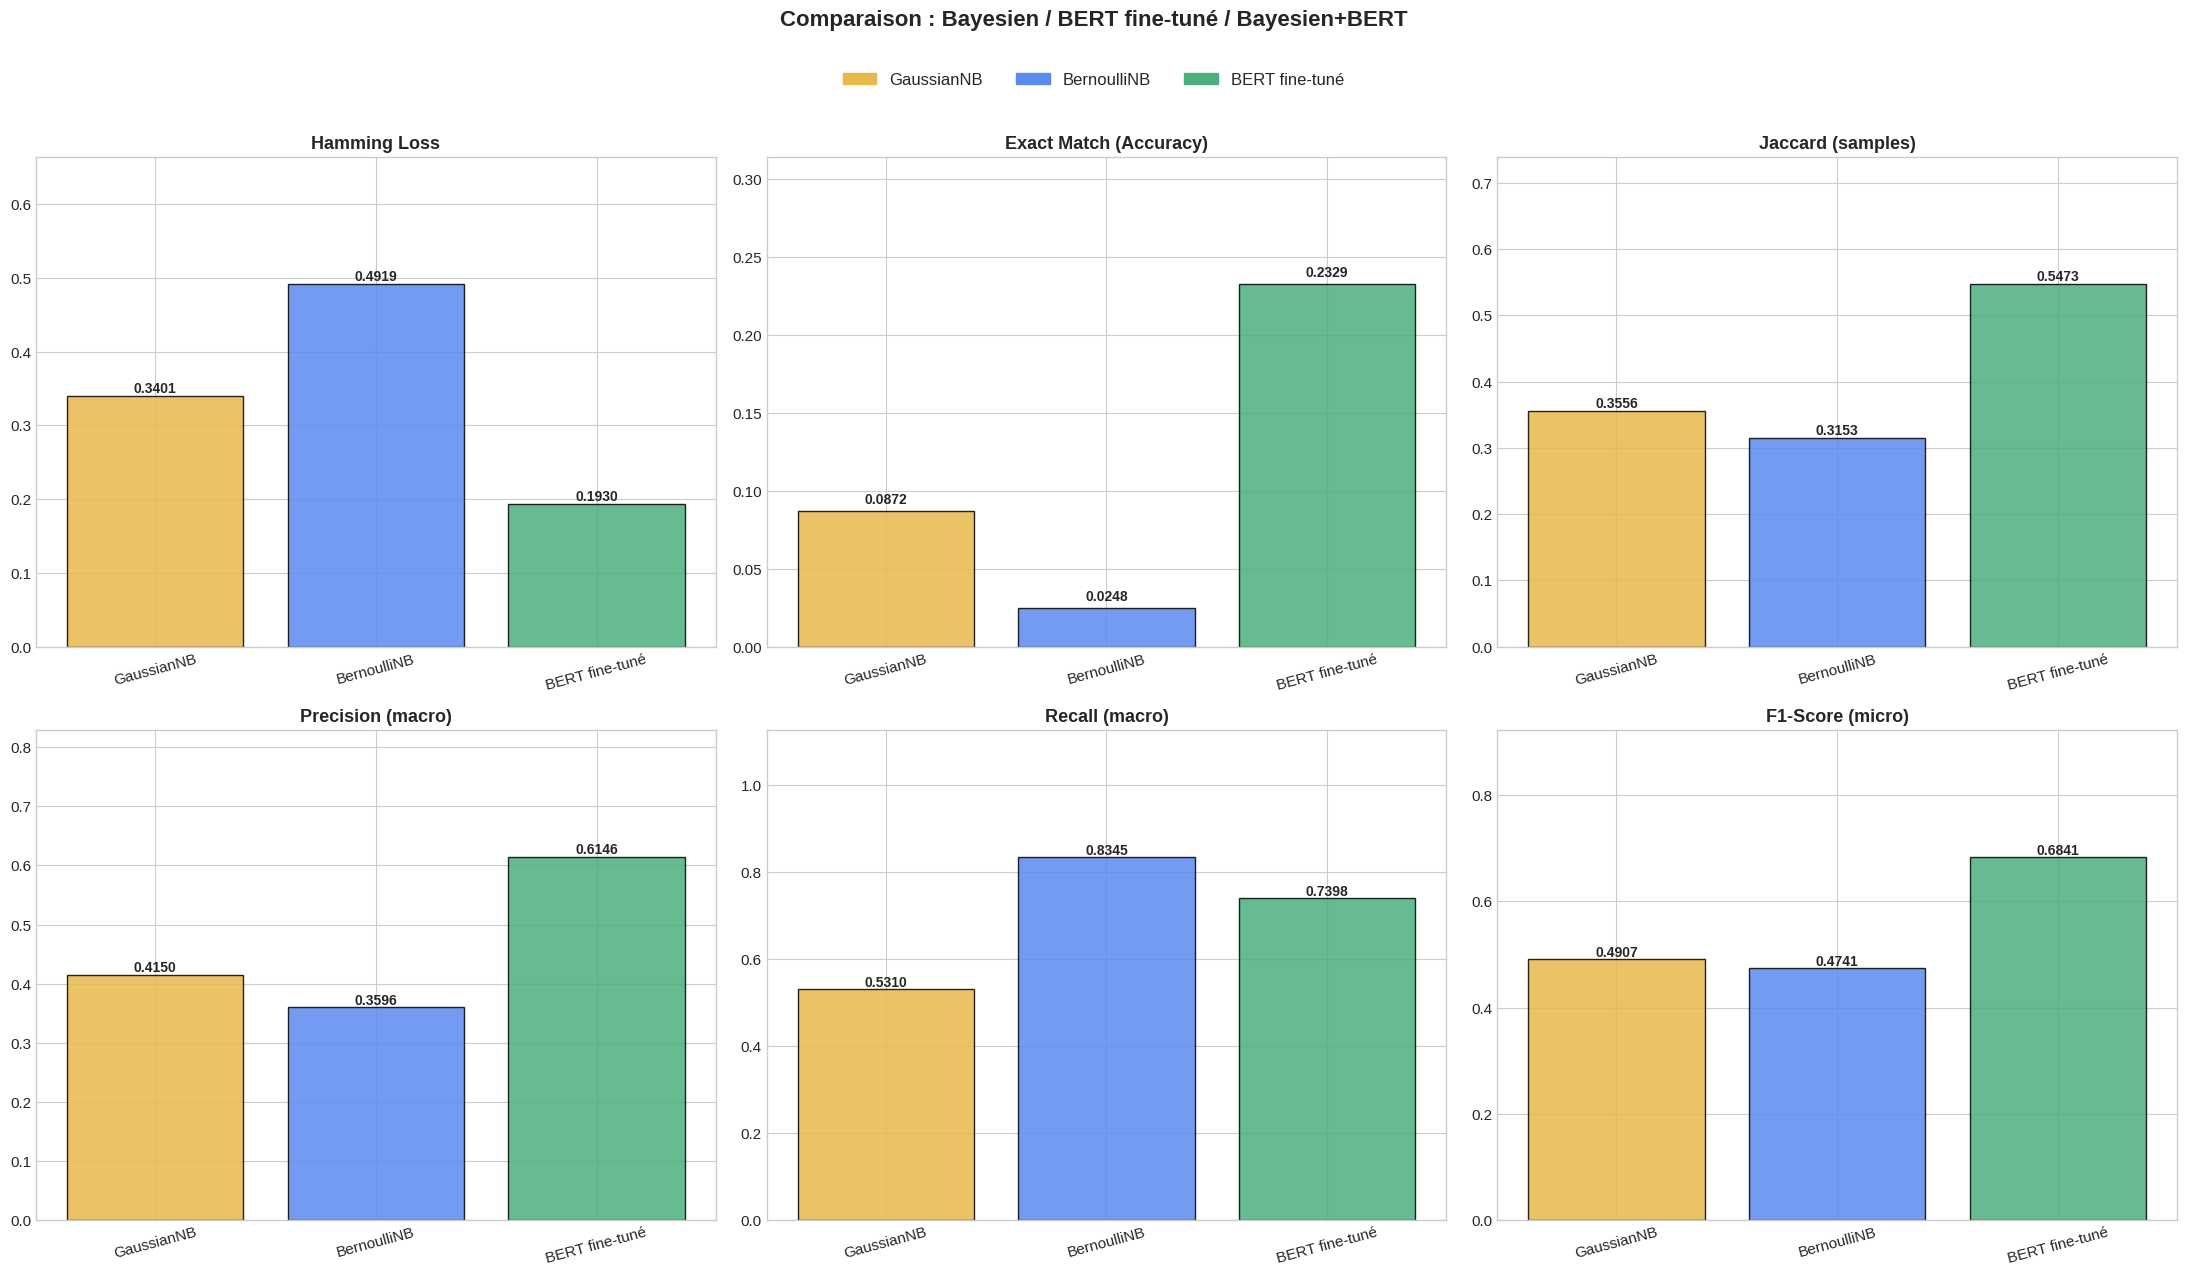


📊 5.3  F1 PAR GENRE — COMPARAISON DES APPROCHES


,GaussianNB,BernoulliNB,BERT fine-tuné
Drama,0.7012,0.6905,0.7551
Comedy,0.5246,0.5456,0.7011
Thriller,0.4203,0.5143,0.6775
Action,0.3287,0.4675,0.6772
Romance,0.3918,0.3834,0.5729
Adventure,0.4337,0.3840,0.6530
Crime,0.2835,0.3210,0.6161


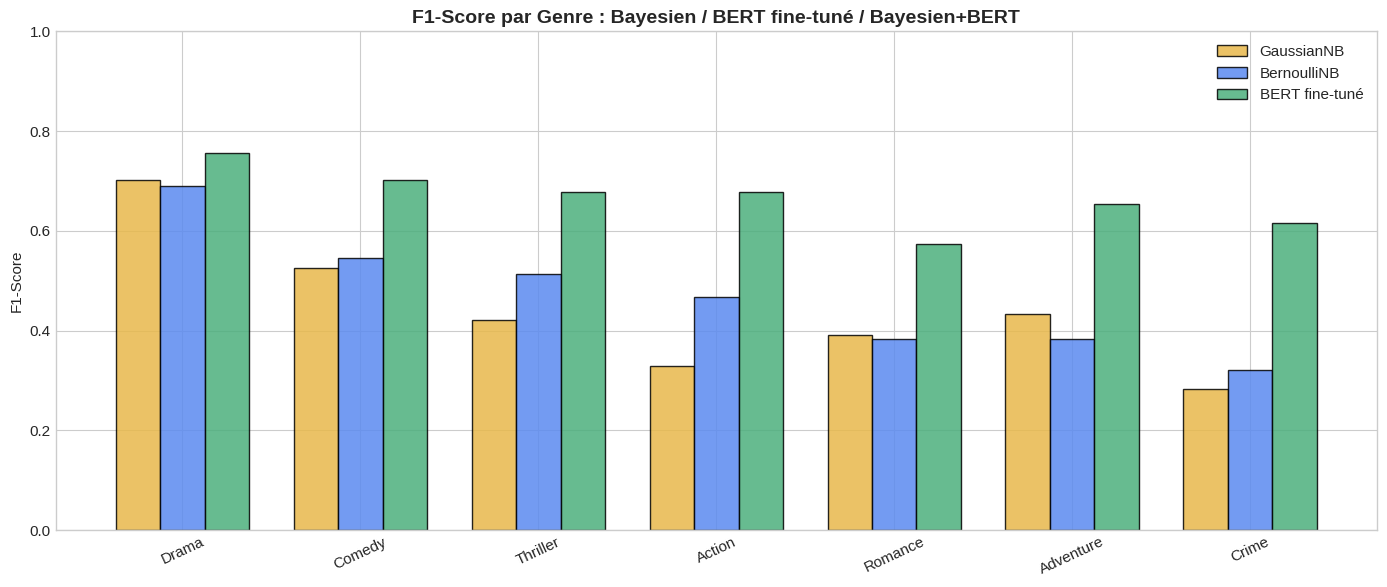


📋 5.4  CLASSIFICATION REPORT — BERT fine-tuné
              precision    recall  f1-score   support

       Drama       0.72      0.80      0.76       513
      Comedy       0.60      0.84      0.70       356
    Thriller       0.59      0.80      0.68       289
      Action       0.59      0.80      0.68       215
     Romance       0.67      0.50      0.57       225
   Adventure       0.60      0.71      0.65       178
       Crime       0.53      0.73      0.62       172

   micro avg       0.62      0.76      0.68      1948
   macro avg       0.61      0.74      0.66      1948
weighted avg       0.63      0.76      0.68      1948
 samples avg       0.63      0.73      0.64      1948


📊 5.5  MATRICES DE CONFUSION PAR GENRE — BERT fine-tuné


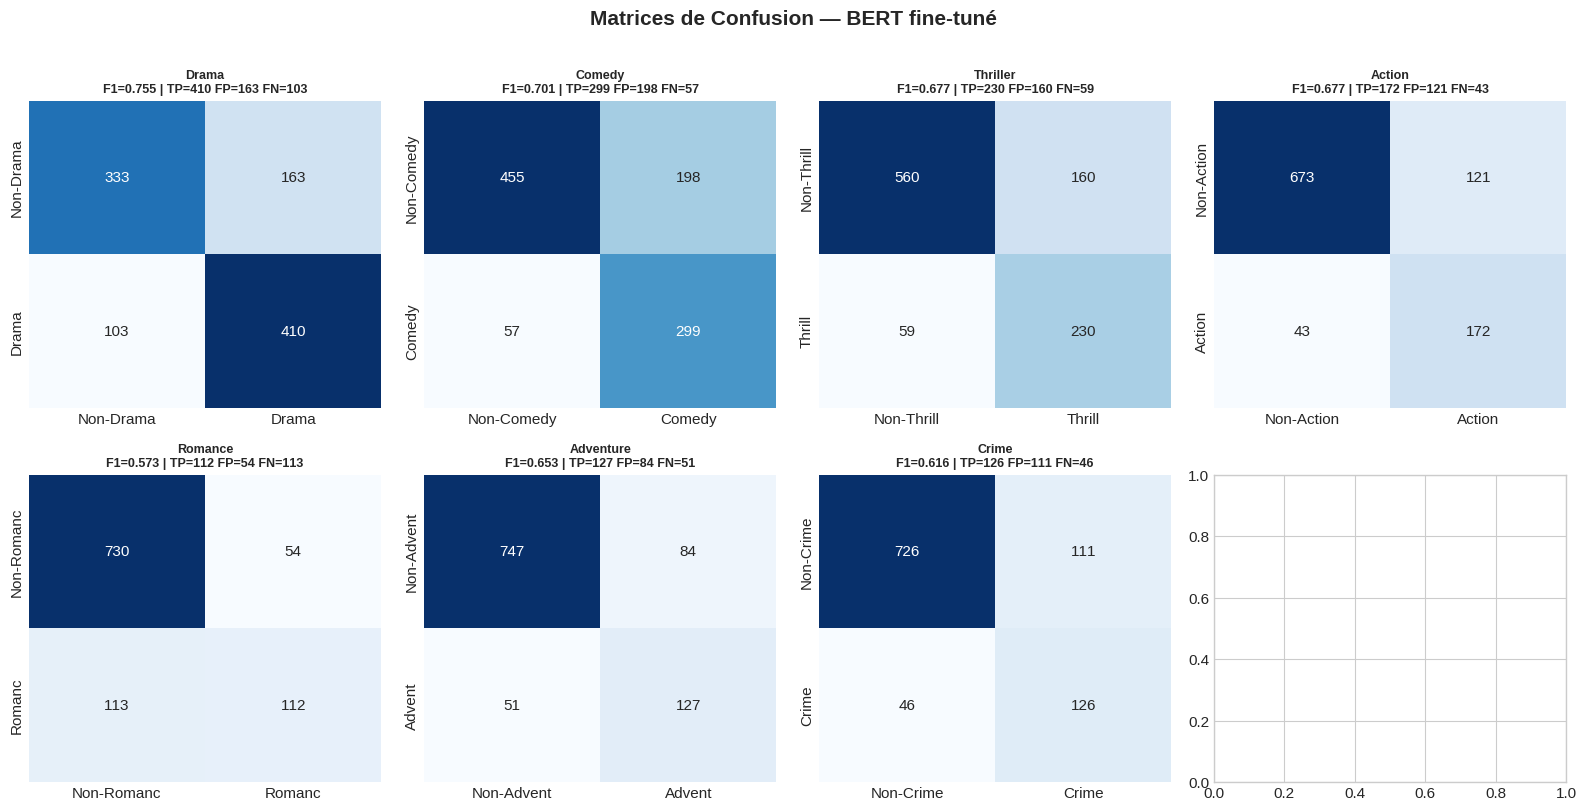


📊 5.6  ANALYSE DÉTAILLÉE PAR GENRE


,Support,Prevalence,TP,FP,FN,TN,Precision,Recall,F1-Score,Confondu avec,Nb confusions
Genre,,,,,,,,,,,
Drama,513,0.5084,410,163,103,333,0.7155,0.7992,0.7551,Comedy,58
Comedy,356,0.3528,299,198,57,455,0.6016,0.8399,0.7011,Drama,32
Thriller,289,0.2864,230,160,59,560,0.5897,0.7958,0.6775,Comedy,40
Action,215,0.2131,172,121,43,673,0.5870,0.8000,0.6772,Drama,27
Adventure,178,0.1764,127,84,51,747,0.6019,0.7135,0.6530,Drama,27
Crime,172,0.1705,126,111,46,726,0.5316,0.7326,0.6161,Drama,31
Romance,225,0.2230,112,54,113,730,0.6747,0.4978,0.5729,Drama,73



✅ GENRES REUSSIS (F1 >= 0.677) :
  🟢 Drama           F1=0.755  P=0.716  R=0.799
  🟢 Comedy          F1=0.701  P=0.602  R=0.840
  🟢 Thriller        F1=0.677  P=0.590  R=0.796
  🟢 Action          F1=0.677  P=0.587  R=0.800

❌ GENRES ECHOUES (F1 < 0.677) :
  🔴 Adventure       F1=0.653  Confondu avec : Drama
  🔴 Crime           F1=0.616  Confondu avec : Drama
  🔴 Romance         F1=0.573  Confondu avec : Drama

📊 5.7  MATRICE DE CO-OCCURRENCE DES GENRES


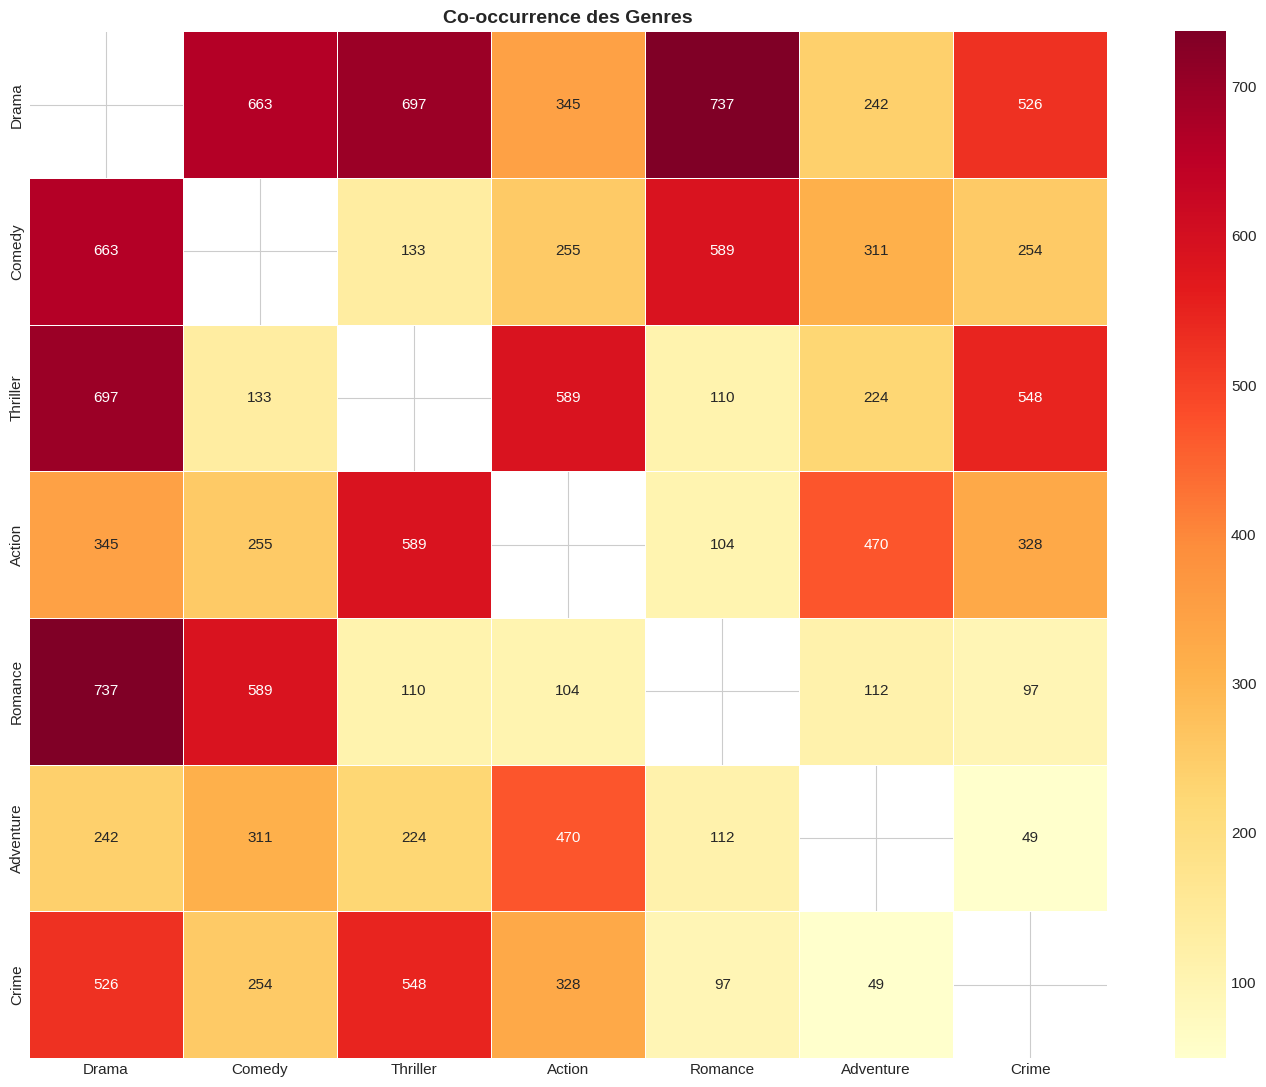


📋 5.8  SYNTHESE FINALE

+-------------------------------------------------------------+
|  Approche           | F1 micro | Exact Match | Hamming Loss |
+-------------------------------------------------------------+
|  GaussianNB          0.4907     0.0872       0.3401    |
|  BernoulliNB         0.4741     0.0248       0.4919    |
|  BERT fine-tuné      0.6841     0.2329       0.1930  🏆|
+-------------------------------------------------------------+

🏆 Meilleur modele : BERT fine-tuné

✅ Analyse complete !


In [8]:
# ============================================================
# 📊 CELLULE 5 — RÉSULTATS & COMPARAISON DES APPROCHES
# ============================================================
# Trois approches comparées :
#   A) Bayésien classique     (features numériques uniquement)
#   B) BERT fine-tuné seul    (multi-label, texte enrichi)
#   C) Bayésien + BERT        (features numériques + OHE BERT)
# ============================================================

# ── 5.1 Métriques Bayésien vs Bayésien+BERT ──────────────────
print('=' * 70)
print('📊 5.1  MÉTRIQUES COMPARATIVES — TOUS LES MODÈLES')
print('=' * 70)

results = {}
for name, y_pred in predictions.items():
    mcm_all = multilabel_confusion_matrix(y_test, y_pred)
    tn = mcm_all[:,0,0].sum(); fp = mcm_all[:,0,1].sum()
    fn = mcm_all[:,1,0].sum(); tp = mcm_all[:,1,1].sum()
    results[name] = {
        'Precision (macro)':           precision_score(y_test, y_pred, average='macro',   zero_division=0),
        'Precision (samples)':         precision_score(y_test, y_pred, average='samples', zero_division=0),
        'Precision (micro)':           precision_score(y_test, y_pred, average='micro',   zero_division=0),
        'False Positives Rate':        fp / (fp + tn) if (fp + tn) > 0 else 0,
        'Label Ranking Loss':          label_ranking_loss(y_test, y_pred),
        'Label Ranking Avg Precision': label_ranking_average_precision_score(y_test, y_pred),
        'Coverage Error':              coverage_error(y_test, y_pred),
        'False Discovery Rate':        fp / (fp + tp) if (fp + tp) > 0 else 0,
        'Hamming Loss':                hamming_loss(y_test, y_pred),
        'Jaccard (macro)':             jaccard_score(y_test, y_pred, average='macro',   zero_division=0),
        'Jaccard (samples)':           jaccard_score(y_test, y_pred, average='samples', zero_division=0),
        'Recall (macro)':              recall_score(y_test, y_pred,  average='macro',   zero_division=0),
        'Recall (micro)':              recall_score(y_test, y_pred,  average='micro',   zero_division=0),
        'Exact Match (Accuracy)':      accuracy_score(y_test, y_pred),
        'F1-Score (micro)':            f1_score(y_test, y_pred, average='micro', zero_division=0),
    }

# ── Évaluation BERT fine-tuné seul ───────────────────────────
if y_pred_bert_saved is not None:
    # Aligner y_pred_bert sur y_test (même split random_state=42)
    y_pred_bert_test = y_pred_bert_saved   # déjà sur le test set

    mcm_b = multilabel_confusion_matrix(y_test, y_pred_bert_test)
    tn_b = mcm_b[:,0,0].sum(); fp_b = mcm_b[:,0,1].sum()
    fn_b = mcm_b[:,1,0].sum(); tp_b = mcm_b[:,1,1].sum()

    results['BERT fine-tuné'] = {
        'Precision (macro)':           precision_score(y_test, y_pred_bert_test, average='macro',   zero_division=0),
        'Precision (samples)':         precision_score(y_test, y_pred_bert_test, average='samples', zero_division=0),
        'Precision (micro)':           precision_score(y_test, y_pred_bert_test, average='micro',   zero_division=0),
        'False Positives Rate':        fp_b / (fp_b + tn_b) if (fp_b + tn_b) > 0 else 0,
        'Label Ranking Loss':          label_ranking_loss(y_test, y_pred_bert_test),
        'Label Ranking Avg Precision': label_ranking_average_precision_score(y_test, y_pred_bert_test),
        'Coverage Error':              coverage_error(y_test, y_pred_bert_test),
        'False Discovery Rate':        fp_b / (fp_b + tp_b) if (fp_b + tp_b) > 0 else 0,
        'Hamming Loss':                hamming_loss(y_test, y_pred_bert_test),
        'Jaccard (macro)':             jaccard_score(y_test, y_pred_bert_test, average='macro',   zero_division=0),
        'Jaccard (samples)':           jaccard_score(y_test, y_pred_bert_test, average='samples', zero_division=0),
        'Recall (macro)':              recall_score(y_test, y_pred_bert_test,  average='macro',   zero_division=0),
        'Recall (micro)':              recall_score(y_test, y_pred_bert_test,  average='micro',   zero_division=0),
        'Exact Match (Accuracy)':      accuracy_score(y_test, y_pred_bert_test),
        'F1-Score (micro)':            f1_score(y_test, y_pred_bert_test, average='micro', zero_division=0),
    }
    predictions['BERT fine-tuné'] = y_pred_bert_test
else:
    print('⚠️  BERT fine-tuné non disponible, ignoré dans la comparaison.')

results_df      = pd.DataFrame(results).T
best_model_name = results_df['F1-Score (micro)'].idxmax()
best_f1         = results_df.loc[best_model_name, 'F1-Score (micro)']

print('\n📊 TABLEAU COMPARATIF COMPLET :')
print('=' * 70)
display(results_df.round(4))
print(f'\n🏆 Meilleur modele (F1 micro) : {best_model_name} ({best_f1:.4f})')

# ── 5.2 Barplots comparatifs ─────────────────────────────────
print('\n' + '=' * 70)
print('📊 5.2  VISUALISATION COMPARAISON DES APPROCHES')
print('=' * 70)

metrics_plot = ['Hamming Loss','Exact Match (Accuracy)','Jaccard (samples)',
                'Precision (macro)','Recall (macro)','F1-Score (micro)']
palette = {'GaussianNB':'#e8b84b','BernoulliNB':'#5b8af0','BERT fine-tuné':'#4caf7d'}

fig, axes = plt.subplots(2, 3, figsize=(22, 12))
for ax, metric in zip(axes.flat, metrics_plot):
    vals   = results_df[metric]
    colors = [palette.get(n, '#888') for n in vals.index]
    bars   = ax.bar(vals.index, vals.values, color=colors, edgecolor='black', alpha=0.85)
    ax.set_title(metric, fontsize=13, fontweight='bold')
    ax.set_ylim(0, max(vals.max() * 1.35, 0.1))
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f'{val:.4f}', ha='center', fontweight='bold', fontsize=10)
    ax.tick_params(axis='x', rotation=15)
fig.legend(
    handles=[plt.Rectangle((0,0),1,1, color=c) for c in palette.values()],
    labels=list(palette.keys()),
    loc='upper center', ncol=3, fontsize=12, bbox_to_anchor=(0.5, 1.02)
)
plt.suptitle('Comparaison : Bayesien / BERT fine-tuné / Bayesien+BERT',
             fontsize=16, fontweight='bold', y=1.06)
plt.tight_layout()
plt.show()

# ── 5.3 F1 par genre — comparaison ───────────────────────────
print('\n' + '=' * 70)
print('📊 5.3  F1 PAR GENRE — COMPARAISON DES APPROCHES')
print('=' * 70)

f1_per_genre = {}
for name, y_pred in predictions.items():
    rep = classification_report(y_test, y_pred,
                                target_names=genre_names,
                                output_dict=True, zero_division=0)
    f1_per_genre[name] = {g: rep[g]['f1-score'] for g in genre_names}

f1_genre_df = pd.DataFrame(f1_per_genre)
display(f1_genre_df.round(4))

fig, ax = plt.subplots(figsize=(14, 6))
x     = np.arange(len(genre_names))
width = 0.25
colors_f1 = ['#e8b84b','#5b8af0','#4caf7d']
for idx2, (name, color) in enumerate(zip(f1_genre_df.columns, colors_f1)):
    ax.bar(x + idx2 * width, f1_genre_df[name], width,
           label=name, color=color, edgecolor='black', alpha=0.85)
ax.set_xticks(x + width)
ax.set_xticklabels(genre_names, rotation=25)
ax.set_ylabel('F1-Score')
ax.set_ylim(0, 1)
ax.set_title('F1-Score par Genre : Bayesien / BERT fine-tuné / Bayesien+BERT',
             fontsize=14, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

# ── 5.4 à 5.8 : inchangés ────────────────────────────────────
print('\n' + '=' * 70)
print(f'📋 5.4  CLASSIFICATION REPORT — {best_model_name}')
print('=' * 70)

y_pred_best = predictions[best_model_name]
print(classification_report(y_test, y_pred_best,
                             target_names=genre_names, zero_division=0))

report_dict = classification_report(y_test, y_pred_best,
                                     target_names=genre_names,
                                     output_dict=True, zero_division=0)
genre_metrics = pd.DataFrame({
    g: {'Precision': report_dict[g]['precision'],
        'Recall':    report_dict[g]['recall'],
        'F1-Score':  report_dict[g]['f1-score'],
        'Support':   report_dict[g]['support']}
    for g in genre_names
}).T.sort_values('F1-Score', ascending=False)

print('\n' + '=' * 70)
print(f'📊 5.5  MATRICES DE CONFUSION PAR GENRE — {best_model_name}')
print('=' * 70)

mcm = multilabel_confusion_matrix(y_test, y_pred_best)
n_cols = 4
n_rows = int(np.ceil(len(genre_names) / n_cols))
fig, axes_cm = plt.subplots(n_rows, n_cols, figsize=(4*n_cols, 4*n_rows))
axes_flat = axes_cm.flat
for i, (genre, ax) in enumerate(zip(genre_names, axes_flat)):
    cm_g = mcm[i]; tn2, fp2, fn2, tp2 = cm_g.ravel()
    sns.heatmap(cm_g, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Non-'+genre[:6], genre[:6]],
                yticklabels=['Non-'+genre[:6], genre[:6]],
                ax=ax, cbar=False)
    f1_g = genre_metrics.loc[genre,'F1-Score'] if genre in genre_metrics.index else 0
    ax.set_title(f'{genre}\nF1={f1_g:.3f} | TP={tp2} FP={fp2} FN={fn2}',
                 fontsize=9, fontweight='bold')
for j in range(i+1, len(list(axes_flat))):
    axes_flat[j].set_visible(False)
plt.suptitle(f'Matrices de Confusion — {best_model_name}',
             fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

print('\n' + '=' * 70)
print('📊 5.6  ANALYSE DÉTAILLÉE PAR GENRE')
print('=' * 70)

genre_analysis = []
for i, genre in enumerate(genre_names):
    cm_g = mcm[i]; tn2, fp2, fn2, tp2 = cm_g.ravel()
    support   = tp2 + fn2
    precision = tp2 / max(tp2 + fp2, 1)
    recall    = tp2 / max(tp2 + fn2, 1)
    f1        = 2 * precision * recall / max(precision + recall, 1e-10)
    prevalence = support / len(y_test)
    mask_fn = (y_test[:,i]==1) & (y_pred_best[:,i]==0)
    if mask_fn.sum() > 0:
        fn_other = y_pred_best[mask_fn].sum(axis=0); fn_other[i] = 0
        confused_genre = genre_names[fn_other.argmax()]
        confused_count = fn_other.max()
    else:
        confused_genre = '-'; confused_count = 0
    genre_analysis.append({
        'Genre': genre, 'Support': support, 'Prevalence': prevalence,
        'TP': tp2, 'FP': fp2, 'FN': fn2, 'TN': tn2,
        'Precision': precision, 'Recall': recall, 'F1-Score': f1,
        'Confondu avec': confused_genre, 'Nb confusions': confused_count,
    })

analysis_df = pd.DataFrame(genre_analysis).set_index('Genre')
analysis_df = analysis_df.sort_values('F1-Score', ascending=False)
display(analysis_df.round(4))

median_f1   = analysis_df['F1-Score'].median()
good_genres = analysis_df[analysis_df['F1-Score'] >= median_f1]
bad_genres  = analysis_df[analysis_df['F1-Score'] <  median_f1]

print(f'\n✅ GENRES REUSSIS (F1 >= {median_f1:.3f}) :')
for genre in good_genres.index:
    row = analysis_df.loc[genre]
    print(f'  🟢 {genre:<15s} F1={row["F1-Score"]:.3f}  P={row["Precision"]:.3f}  R={row["Recall"]:.3f}')

print(f'\n❌ GENRES ECHOUES (F1 < {median_f1:.3f}) :')
for genre in bad_genres.index:
    row = analysis_df.loc[genre]
    print(f'  🔴 {genre:<15s} F1={row["F1-Score"]:.3f}  Confondu avec : {row["Confondu avec"]}')

print('\n' + '=' * 70)
print('📊 5.7  MATRICE DE CO-OCCURRENCE DES GENRES')
print('=' * 70)

cooccurrence    = np.dot(y_multilabel.T, y_multilabel)
cooccurrence_df = pd.DataFrame(cooccurrence, index=genre_names, columns=genre_names)
fig, ax = plt.subplots(figsize=(14, 11))
mask_diag = np.zeros_like(cooccurrence_df, dtype=bool)
np.fill_diagonal(mask_diag, True)
sns.heatmap(cooccurrence_df, annot=True, fmt='.0f', cmap='YlOrRd',
            mask=mask_diag, ax=ax, linewidths=0.5)
ax.set_title('Co-occurrence des Genres', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print('\n' + '=' * 70)
print('📋 5.8  SYNTHESE FINALE')
print('=' * 70)
print('\n+-------------------------------------------------------------+')
print('|  Approche           | F1 micro | Exact Match | Hamming Loss |')
print('+-------------------------------------------------------------+')
for name in results_df.index:
    f1m  = results_df.loc[name,'F1-Score (micro)']
    em   = results_df.loc[name,'Exact Match (Accuracy)']
    hl   = results_df.loc[name,'Hamming Loss']
    star = ' 🏆' if name == best_model_name else '   '
    print(f'|  {name:<18s}  {f1m:.4f}     {em:.4f}       {hl:.4f} {star}|')
print('+-------------------------------------------------------------+')
print(f'\n🏆 Meilleur modele : {best_model_name}')
print('\n✅ Analyse complete !')


In [9]:
# ============================================================
# 🖥️ CELLULE 6 — INTERFACE GRAPHIQUE INTERACTIVE
# ============================================================

# ── 6.0 Construction des listes acteurs / réalisateurs ───────
def _build_people_lists(df_raw):
    actors = {}
    for col in ['actor_1_name','actor_2_name','actor_3_name']:
        likes_col = col.replace('_name','_facebook_likes')
        if col in df_raw.columns and likes_col in df_raw.columns:
            for _, row in df_raw[[col,likes_col]].dropna().iterrows():
                name = str(row[col]).strip(); likes = float(row[likes_col])
                if name and name.lower() not in ('nan',''):
                    if name not in actors or actors[name] < likes:
                        actors[name] = likes
    directors = {}
    if 'director_name' in df_raw.columns and 'director_facebook_likes' in df_raw.columns:
        for _, row in df_raw[['director_name','director_facebook_likes']].dropna().iterrows():
            name = str(row['director_name']).strip(); likes = float(row['director_facebook_likes'])
            if name and name.lower() not in ('nan',''):
                if name not in directors or directors[name] < likes:
                    directors[name] = likes
    return actors, directors

try:
    ACTORS_DICT, DIRECTORS_DICT = _build_people_lists(df_raw)
    ACTORS_LIST    = sorted(ACTORS_DICT.keys())
    DIRECTORS_LIST = sorted(DIRECTORS_DICT.keys())
except Exception as e:
    print(f'Fallback : {e}')
    ACTORS_LIST    = ['Tom Hanks','Leonardo DiCaprio','Scarlett Johansson','Brad Pitt','Meryl Streep']
    DIRECTORS_LIST = ['Steven Spielberg','Christopher Nolan','James Cameron','Martin Scorsese']
    ACTORS_DICT    = {a: random.randint(5000,100000) for a in ACTORS_LIST}
    DIRECTORS_DICT = {d: random.randint(5000,50000)  for d in DIRECTORS_LIST}

# ── 6.1 CSS ───────────────────────────────────────────────────
CSS = (
    "<style>"
    ".pred-app{font-family:'Segoe UI',sans-serif;max-width:920px;margin:0 auto;color:#1a1a2e;}"
    ".pred-title{font-size:22px;font-weight:700;color:#1a1a2e;margin-bottom:4px;}"
    ".pred-subtitle{font-size:13px;color:#888;margin-bottom:20px;}"
    ".pred-section-label{font-size:11px;font-weight:600;letter-spacing:2px;text-transform:uppercase;color:#555;margin:16px 0 6px;}"
    ".pred-models-grid{display:grid;grid-template-columns:repeat(2,1fr);gap:14px;margin-top:18px;}"
    ".pred-model-card{border-radius:12px;padding:16px 18px;border:1.5px solid #e0e0e0;background:#fafafa;}"
    ".pred-model-card.gnb{border-color:#f0c040;background:#fffdf0;}"
    ".pred-model-card.bnb{border-color:#7eb8f7;background:#f0f7ff;}"
    ".pred-model-title{font-size:11px;font-weight:700;letter-spacing:1.5px;text-transform:uppercase;margin-bottom:10px;padding-bottom:8px;border-bottom:1px solid #e8e8e8;}"
    ".pred-model-card.gnb .pred-model-title{color:#b8860b;}"
    ".pred-model-card.bnb .pred-model-title{color:#1a6fc4;}"
    ".pred-genre-row{display:flex;align-items:center;gap:8px;margin:5px 0;}"
    ".pred-genre-name{width:82px;font-size:12px;flex-shrink:0;}"
    ".pred-bar-bg{flex:1;height:8px;background:#e8e8e8;border-radius:4px;overflow:hidden;}"
    ".pred-bar-fill{height:100%;border-radius:4px;}"
    ".pred-pct{width:32px;font-size:11px;color:#888;text-align:right;}"
    ".pred-badge{display:inline-block;padding:3px 10px;border-radius:20px;font-size:11px;font-weight:700;letter-spacing:1px;text-transform:uppercase;margin:2px 2px 8px;}"
    ".pred-badge.gnb{background:#f0c040;color:#5a3e00;}"
    ".pred-badge.bnb{background:#7eb8f7;color:#0a2a5c;}"
    ".pred-info-bar{display:flex;flex-wrap:wrap;gap:10px;margin-top:18px;}"
    ".pred-info-chip{background:#f4f4f4;border:1px solid #e0e0e0;border-radius:20px;padding:4px 14px;font-size:12px;color:#444;}"
    "</style>"
)

# ── 6.2 Helpers ───────────────────────────────────────────────
GENRE_COLORS = {
    'Action':'#e05252','Adventure':'#e8834b','Comedy':'#f0c040',
    'Drama':'#5b8af0','Crime':'#9b59b6','Romance':'#e84b8a','Thriller':'#4bcde8',
}

def _build_num_vec(actor_names, director_name, budget_m, duration, title_year):
    a_likes = sorted([ACTORS_DICT.get(a, 5000) for a in actor_names], reverse=True)
    while len(a_likes) < 3: a_likes.append(5000)
    dir_likes  = DIRECTORS_DICT.get(director_name, 5000)
    cast_total = sum(a_likes)
    budget     = budget_m * 1_000_000
    gross      = budget * random.uniform(1.2, 3.5)
    base_imdb  = 6.2
    if budget > 50_000_000:   base_imdb += 0.3
    if budget > 150_000_000:  base_imdb += 0.2
    if cast_total > 50_000:   base_imdb += 0.2
    if dir_likes  > 10_000:   base_imdb += 0.1
    if 90 <= duration <= 140: base_imdb += 0.1
    imdb_score = round(min(base_imdb + random.uniform(-0.3, 0.4), 9.5), 1)
    base = {
        'num_critic_for_reviews': 200, 'duration': duration,
        'director_facebook_likes': dir_likes,
        'actor_3_facebook_likes': a_likes[2], 'actor_1_facebook_likes': a_likes[0],
        'gross': gross, 'num_voted_users': cast_total * 10,
        'cast_total_facebook_likes': cast_total, 'facenumber_in_poster': len(actor_names),
        'num_user_for_reviews': 500, 'budget': budget, 'title_year': title_year,
        'actor_2_facebook_likes': a_likes[1], 'imdb_score': imdb_score,
        'movie_facebook_likes': cast_total * 2, 'nb_genres': 2,
    }
    # 16 features numériques
    num_vec    = np.array([base.get(f, 0.0) for f in features_disponibles]).reshape(1, -1)
    # 7 colonnes BERT_* à zéro (le scaler a été fitté sur X_combined = num + BERT)
    bert_zeros = np.zeros((1, len(GENRE_NAMES)))
    vec        = np.concatenate([num_vec, bert_zeros], axis=1)
    return vec, imdb_score

def _predict_all_models(actor_names, director_name, budget_m, duration, title_year):
    vec, imdb_score = _build_num_vec(actor_names, director_name, budget_m, duration, title_year)
    vec_scaled = scaler_std.transform(vec)
    results = {}
    for name, info in models.items():
        try:
            probas = {}
            for j, genre in enumerate(genre_names):
                p = info['model'].estimators_[j].predict_proba(vec_scaled)[0][1]
                probas[genre] = float(p)
            results[name] = probas
        except Exception:
            results[name] = {g: 0.0 for g in genre_names}
    return results, imdb_score

def _top_genres(proba_dict, threshold=0.45):
    above = [(g, p) for g, p in proba_dict.items() if p >= threshold]
    if not above:
        top = max(proba_dict, key=proba_dict.get)
        above = [(top, proba_dict[top])]
    return sorted(above, key=lambda x: -x[1])

def _render_card(name, proba_dict, css_class, label):
    top     = _top_genres(proba_dict)
    top_set = {g for g, _ in top}
    badges  = ''.join(f'<span class="pred-badge {css_class}">{g}</span>' for g, _ in top)
    if not badges: badges = '<span style="font-size:12px;color:#aaa;font-style:italic">Aucun genre détecté</span>'
    bars = ''
    for g in sorted(proba_dict, key=lambda x: -proba_dict[x]):
        p   = proba_dict[g]; pct = int(p * 100)
        col = GENRE_COLORS.get(g, '#aaa')
        bold    = 'font-weight:700;color:#111' if g in top_set else 'color:#aaa'
        opacity = '1' if g in top_set else '0.25'
        bars += (
            f'<div class="pred-genre-row">'
            f'<div class="pred-genre-name" style="{bold}">{g}</div>'
            f'<div class="pred-bar-bg"><div class="pred-bar-fill" style="width:{pct}%;background:{col};opacity:{opacity}"></div></div>'
            f'<div class="pred-pct">{pct}%</div>'
            f'</div>'
        )
    return (
        f'<div class="pred-model-card {css_class}">'
        f'<div class="pred-model-title">{label}</div>'
        f'<div style="margin-bottom:10px">{badges}</div>'
        f'{bars}</div>'
    )

# ── 6.3 Widgets ───────────────────────────────────────────────
selected_actors   = []
selected_director = [DIRECTORS_LIST[0] if DIRECTORS_LIST else 'Unknown']

actor_search   = widgets.Text(placeholder='Rechercher un acteur...', layout=widgets.Layout(width='260px'))
actor_dropdown = widgets.Dropdown(options=ACTORS_LIST[:80], description='', layout=widgets.Layout(width='260px'), style={'description_width':'0px'})
add_actor_btn  = widgets.Button(description='+ Ajouter', layout=widgets.Layout(width='110px'))
actors_select  = widgets.SelectMultiple(options=[], rows=4, layout=widgets.Layout(width='380px'))
remove_btn     = widgets.Button(description='x Retirer', button_style='danger', layout=widgets.Layout(width='110px'))

director_search   = widgets.Text(placeholder='Rechercher un réalisateur...', layout=widgets.Layout(width='260px'))
director_dropdown = widgets.Dropdown(options=DIRECTORS_LIST[:80], description='', layout=widgets.Layout(width='260px'), style={'description_width':'0px'})

budget_slider   = widgets.IntSlider(value=50,   min=1,    max=400,  step=1, description='Budget ($M)',  style={'description_width':'110px'}, layout=widgets.Layout(width='460px'))
duration_slider = widgets.IntSlider(value=110,  min=60,   max=210,  step=1, description='Durée (min)',  style={'description_width':'110px'}, layout=widgets.Layout(width='460px'))
year_slider     = widgets.IntSlider(value=2024, min=1980, max=2027, step=1, description='Année sortie', style={'description_width':'110px'}, layout=widgets.Layout(width='460px'))

predict_btn = widgets.Button(description='Prédire les genres', layout=widgets.Layout(width='240px', height='42px'))
predict_btn.style.button_color = '#1a6fc4'
predict_btn.style.font_weight  = 'bold'
result_out = widgets.Output()

# ── 6.4 Callbacks ─────────────────────────────────────────────
def _filter(change, lst, dd):
    q = change['new'].strip().lower()
    dd.options = ([n for n in lst if q in n.lower()] if q else lst)[:80]
    if dd.options: dd.value = dd.options[0]

actor_search.observe(lambda c: _filter(c, ACTORS_LIST, actor_dropdown), names='value')
director_search.observe(lambda c: _filter(c, DIRECTORS_LIST, director_dropdown), names='value')
director_dropdown.observe(lambda c: selected_director.__setitem__(0, c['new']), names='value')
if director_dropdown.options: selected_director[0] = director_dropdown.options[0]

def _refresh():
    actors_select.options = [f"{n}  ({int(ACTORS_DICT.get(n,0)):,} likes)" for n in selected_actors]

def add_actor(b):
    name = actor_dropdown.value
    if name and name not in selected_actors and len(selected_actors) < 5:
        selected_actors.append(name); _refresh()

def remove_actor(b):
    for label in actors_select.value:
        name = label.split('  (')[0]
        if name in selected_actors: selected_actors.remove(name)
    _refresh()

add_actor_btn.on_click(add_actor)
remove_btn.on_click(remove_actor)

# ── 6.5 Prédiction ────────────────────────────────────────────
def on_predict(b):
    with result_out:
        clear_output(wait=True)
        if not selected_actors:
            display(HTML('<p style="color:#c0392b;font-family:sans-serif">Veuillez ajouter au moins un acteur.</p>'))
            return
        director = selected_director[0] or DIRECTORS_LIST[0]
        try:
            all_probas, imdb_est = _predict_all_models(
                selected_actors, director,
                budget_slider.value, duration_slider.value, year_slider.value
            )
        except Exception as e:
            display(HTML(f'<p style="color:#c0392b">Erreur : {e}</p>'))
            return
        cards_html = ''
        card_defs = [
            ('GaussianNB',  'gnb', 'GaussianNB — Bayésien numérique'),
            ('BernoulliNB', 'bnb', 'BernoulliNB — Bayésien discret'),
        ]
        for key, css, label in card_defs:
            if key in all_probas:
                cards_html += _render_card(key, all_probas[key], css, label)
        actors_str = ', '.join(selected_actors)
        dur_label  = 'Court' if duration_slider.value < 90 else ('Standard' if duration_slider.value <= 140 else 'Épique')
        html = (
            '<div class="pred-app">'
            '<div class="pred-title">Résultats de prédiction</div>'
            '<div class="pred-info-bar">'
            f'<span class="pred-info-chip">Acteurs : {actors_str}</span>'
            f'<span class="pred-info-chip">Réalisateur : {director}</span>'
            f'<span class="pred-info-chip">Budget : {budget_slider.value}M$</span>'
            f'<span class="pred-info-chip">Durée : {duration_slider.value} min ({dur_label})</span>'
            f'<span class="pred-info-chip">Année : {year_slider.value}</span>'
            f'<span class="pred-info-chip">IMDB estimé : {imdb_est}</span>'
            '</div>'
            '<div class="pred-section-label">Genres prédits par modèle</div>'
            f'<div class="pred-models-grid">{cards_html}</div>'
            '</div>'
        )
        display(HTML(CSS + html))

predict_btn.on_click(on_predict)

# ── 6.6 Affichage ─────────────────────────────────────────────
display(HTML(CSS + '<div class="pred-app"><div class="pred-title">Prédicteur de genres</div><div class="pred-subtitle">Remplissez les informations du film puis cliquez sur Prédire.</div></div>'))

display(HTML('<div style="font-family:sans-serif;font-size:11px;font-weight:600;letter-spacing:2px;text-transform:uppercase;color:#555;margin:16px 0 6px">Casting — acteurs</div>'))
display(widgets.HBox([
    widgets.VBox([actor_search, actor_dropdown]),
    widgets.VBox([widgets.Label(''), add_actor_btn], layout=widgets.Layout(justify_content='flex-end', padding='0 0 0 10px')),
], layout=widgets.Layout(align_items='flex-start')))
display(HTML('<div style="font-family:sans-serif;font-size:11px;color:#888;margin:6px 0 4px">Acteurs sélectionnés — Ctrl+clic pour multi-sélectionner puis Retirer</div>'))
display(widgets.HBox([actors_select, widgets.VBox([remove_btn], layout=widgets.Layout(justify_content='flex-end', padding='0 0 0 10px'))]))

display(HTML('<div style="font-family:sans-serif;font-size:11px;font-weight:600;letter-spacing:2px;text-transform:uppercase;color:#555;margin:18px 0 6px">Réalisateur</div>'))
display(widgets.HBox([director_search, director_dropdown]))

display(HTML('<div style="font-family:sans-serif;font-size:11px;font-weight:600;letter-spacing:2px;text-transform:uppercase;color:#555;margin:18px 0 6px">Paramètres du film</div>'))
display(widgets.VBox([budget_slider, duration_slider, year_slider]))

display(widgets.HBox([predict_btn], layout=widgets.Layout(justify_content='flex-start', margin='20px 0 8px')))
display(result_out)


Output()